<a href="https://colab.research.google.com/github/Johan-pp/Clase-S15/blob/main/S23_Streamlit_Observatorio_Financiero_Laboratorio_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📈 S23 · Laboratorio de Streamlit: Mi Observatorio Financiero
**Lenguajes de Programación · Ingeniería Financiera · Google Colab · Taller 6**

> **Reto:** convertir un análisis en Python en una aplicación web que permita elegir activos, comparar su comportamiento y explicar los resultados.

**Al finalizar podrás:** crear una interfaz, distribuir contenido con `st.columns`, organizar pestañas con `st.tabs`, agregar imágenes, capturar decisiones del usuario, representar series financieras y guardar tu aplicación en GitHub.

**Cómo trabajar:** ejecuta las celdas en orden. Las celdas `%%writefile app.py` **reemplazan** el archivo por una versión nueva; antes de avanzar se guarda una copia. El servidor se inicia una sola vez y detecta cambios en `app.py`.

**Importante:** Colab ejecuta Python en un equipo remoto. El archivo `app.py` se modifica en el entorno de Colab; la interfaz se visualiza en otra pestaña del navegador. No se requiere instalar Python en tu computador.

## 01 · Preparar el entorno

**¿Qué es Streamlit?** Una biblioteca de Python que convierte instrucciones como `st.title()` o `st.selectbox()` en componentes de una página web.

| En un notebook | En Streamlit |
|---|---|
| `print(resultado)` muestra texto en una celda | `st.metric()` muestra un indicador |
| `df.plot()` crea un gráfico en el notebook | `st.line_chart()` lo presenta en la aplicación |
| Se cambian variables editando código | El usuario cambia parámetros con controles |

Primero instalamos las bibliotecas. **No ejecutes `streamlit run` directamente con `!` sin segundo plano**, porque la celda quedaría ocupada.

In [1]:
%pip -q install "streamlit>=1.38,<2" "yfinance>=0.2.50,<2" "plotly>=5.24,<7" "pandas>=2.1,<3" "numpy>=1.26,<3" pillow requests

In [2]:
import sys, streamlit, pandas, numpy, plotly, yfinance
print("Python:", sys.version.split()[0])
print("Streamlit:", streamlit.__version__)
print("Pandas:", pandas.__version__)
print("Plotly:", plotly.__version__)
print("yfinance:", yfinance.__version__)

Python: 3.13.18
Streamlit: 1.66.1
Pandas: 2.2.3
Plotly: 5.24.1
yfinance: 0.2.66


## 02 · Primera aplicación: título y mensaje

`st.title()` crea un título grande; `st.write()` presenta contenido; `st.info()` destaca un mensaje. Observa cómo cada instrucción de Python se convierte en una parte visible de la página.

**Actividad:** cambia el título por el nombre de tu proyecto y agrega una frase que explique qué problema financiero quieres analizar.

In [3]:
%%writefile app.py
import streamlit as st

st.set_page_config(page_title="Mi Observatorio Financiero", page_icon="📈", layout="wide")
st.title("📈 Mi Observatorio Financiero")
st.write("Una aplicación creada con Python y Streamlit.")
st.info("Hoy aprenderemos a construir esta interfaz paso a paso.")


Writing app.py


### Guardar una versión recuperable

Cada etapa conserva una copia. Si algo falla, podrás recuperar una versión funcional sin empezar de nuevo.

In [4]:
from pathlib import Path
from datetime import datetime
Path("versiones").mkdir(exist_ok=True)
Path("versiones/01_primera_app.py").write_text(Path("app.py").read_text(encoding="utf-8"), encoding="utf-8")
print("Versión 01 guardada")

Versión 01 guardada


## 03 · Iniciar Streamlit y comprobar que responde

El servidor se ejecutará **en segundo plano** y la celda terminará. Después verificaremos la dirección local `http://127.0.0.1:8501/_stcore/health`.

**No avances al túnel si la comprobación no muestra `200 / ok`.**

In [5]:
import subprocess, time, requests
from pathlib import Path

# Evita dejar varios servidores compitiendo por el puerto 8501.
subprocess.run(["pkill", "-f", "[s]treamlit run app.py"], check=False)
log_streamlit = open("/tmp/s23_streamlit.log", "w")
servidor = subprocess.Popen(
    ["streamlit", "run", "app.py", "--server.port=8501", "--server.address=0.0.0.0", "--server.headless=true", "--server.fileWatcherType=poll"],
    stdout=log_streamlit, stderr=subprocess.STDOUT, start_new_session=True
)

for intento in range(20):
    try:
        respuesta = requests.get("http://127.0.0.1:8501/_stcore/health", timeout=2)
        if respuesta.status_code == 200:
            print("✅ Streamlit funcionando:", respuesta.status_code, respuesta.text)
            break
    except requests.RequestException:
        pass
    time.sleep(1)
else:
    print("❌ No responde Streamlit. Últimos mensajes:")
    print(Path("/tmp/s23_streamlit.log").read_text(errors="replace")[-3000:])

✅ Streamlit funcionando: 200 ok


## 04 · Abrir la aplicación en el navegador

En sesiones anteriores, **LocalTunnel produjo errores 502** y no cargó los módulos JavaScript de `multiselect` y `dataframe`. Por eso aquí usamos **Cloudflare Quick Tunnel**, también temporal.

**Limitación:** no podemos garantizar la disponibilidad de un túnel externo en todas las sesiones de Colab. Si falla, conserva el código y utiliza el despliegue alternativo en Streamlit Community Cloud al final del laboratorio.

In [6]:
import platform, urllib.request, os
from pathlib import Path
arquitectura = platform.machine().lower()
archivo = {"x86_64":"cloudflared-linux-amd64", "aarch64":"cloudflared-linux-arm64"}.get(arquitectura)
if not archivo:
    raise RuntimeError(f"Arquitectura no contemplada: {arquitectura}")
url = f"https://github.com/cloudflare/cloudflared/releases/latest/download/{archivo}"
if not Path("/tmp/cloudflared").exists():
    urllib.request.urlretrieve(url, "/tmp/cloudflared")
os.chmod("/tmp/cloudflared", 0o755)
print("Cloudflared preparado para", arquitectura)

Cloudflared preparado para x86_64


In [7]:
import re, subprocess, time
from pathlib import Path
subprocess.run(["pkill", "-f", "[c]loudflared tunnel --url"], check=False)
registro = open("/tmp/s23_cloudflare.log", "w")
tunel = subprocess.Popen(
    ["/tmp/cloudflared", "tunnel", "--url", "http://127.0.0.1:8501", "--no-autoupdate"],
    stdout=registro, stderr=subprocess.STDOUT, start_new_session=True
)
url_publica = None
for intento in range(25):
    time.sleep(1)
    texto = Path("/tmp/s23_cloudflare.log").read_text(errors="replace")
    encontrado = re.search(r"https://[a-zA-Z0-9-]+\.trycloudflare\.com", texto)
    if encontrado:
        url_publica = encontrado.group(0)
        break
if url_publica:
    print("🌐 ABRE TU APLICACIÓN EN UNA PESTAÑA NUEVA:", url_publica)
else:
    print("No se obtuvo URL. Diagnóstico:")
    print(texto[-2500:])

🌐 ABRE TU APLICACIÓN EN UNA PESTAÑA NUEVA: https://collectible-integrate-walls-incurred.trycloudflare.com


**Comprobación visual:** al abrir el enlace debe verse el título **Mi Observatorio Financiero**. Si aparece `502 Bad Gateway`, ejecuta el diagnóstico siguiente; no modifiques el código de la aplicación todavía.

In [8]:
from pathlib import Path
import requests
try:
    r = requests.get("http://127.0.0.1:8501/_stcore/health", timeout=5)
    print("Servidor local:", r.status_code, r.text)
except Exception as e:
    print("Servidor local sin respuesta:", e)
print("\nRegistro Streamlit:\n", Path("/tmp/s23_streamlit.log").read_text(errors="replace")[-900:])
print("\nRegistro Cloudflare:\n", Path("/tmp/s23_cloudflare.log").read_text(errors="replace")[-900:])

Servidor local: 200 ok

Registro Streamlit:
 

2026-11-05 03:22:07.783 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.106.149.161:8501



Registro Cloudflare:
 tocol quic
2026-11-05T03:22:12Z INF ICMP proxy will use 172.28.0.12 as source for IPv4
2026-11-05T03:22:12Z INF ICMP proxy will use ::1 in zone lo as source for IPv6
2026/11/05 03:22:12 failed to sufficiently increase receive buffer size (was: 208 kiB, wanted: 7168 kiB, got: 416 kiB). See https://github.com/quic-go/quic-go/wiki/UDP-Buffer-Sizes for details.
2026-11-05T03:22:12Z INF ICMP proxy will use 172.28.0.12 as source for IPv4
2026-11-05T03:22:12Z INF ICMP proxy will use ::1 in zone lo as source for IPv6
2026-11-05T03:22:12Z INF Starting metrics server on 127.0.0.1:20241/metrics
2026-11-05T03:22:12Z INF Tunnel connection curve preferences: [X25519MLKEM768 CurveID(65074) CurveP2

## 05 · Diseñar el layout: barra lateral, columnas y pestañas

**Layout** significa la distribución de los componentes en pantalla.

- `st.sidebar`: panel lateral para configurar el análisis.
- `st.columns(2)`: divide una sección en dos columnas.
- `st.tabs([...])`: organiza contenidos en pestañas.
- `with`: indica en qué columna o pestaña aparecerá cada elemento.

**Antes de ejecutar:** predice dónde aparecerá cada texto. Después abre el navegador y verifica.

In [24]:
%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np
import yfinance as yf
import plotly.express as px

# Configuración de página de alto estándar institucional
st.set_page_config(page_title="Observatorio Financiero Premium", page_icon="🏛️", layout="wide")

# Estilo CSS de Nivel Corporativo Premium
st.markdown("""<style>
[data-testid="stApp"]{background:linear-gradient(145deg,#0A192F,#0D1B2A);color:#E2E8F0}
[data-testid="stSidebar"]{background:#030712;border-right:2px solid #F5A623}
[data-testid="stMetric"]{background:#0F172A;padding:20px;border-radius:14px;border:1.5px solid #F5A623;box-shadow: 0px 4px 10px rgba(245, 166, 35, 0.1)}
h1, h2, h3 {color:#F5A623;font-family:'Georgia',serif;font-weight:700}
.stTabs [data-baseweb="tab"]{color:#64FFDA;font-weight:600}
</style>""", unsafe_allow_html=True)

# Mostrar banner corporativo generado con Pillow
st.image("assets/banner_financiero.png", use_container_width=True)
st.title("🏛️ Observatorio Financiero Premium")
st.caption("Análisis de Alta Gama · Herramientas Profesionales de Simulación y Mercado Real")

UNIVERSO = ["AAPL", "MSFT", "NVDA", "JPM", "GOOGL", "SPY", "GLD"]
st.sidebar.header("⚙️ Configuración Corporativa")
tickers = st.sidebar.multiselect("Seleccione Activos de Análisis", UNIVERSO, default=["AAPL", "MSFT", "JPM"], max_selections=5)
periodo = st.sidebar.selectbox("Horizonte Histórico", ["3mo", "6mo", "1y", "2y"], index=2,
    format_func=lambda x: {"3mo":"3 meses", "6mo":"6 meses", "1y":"1 año", "2y":"2 años"}[x])
capital = st.sidebar.number_input("Capital de Inversión Inicial (USD)", min_value=100.0, value=10000.0, step=1000.0)
fuente = st.sidebar.radio("Fuente de Datos", ["Yahoo Finance (Mercado Real)", "Simulados (Modelación de Práctica)"], index=0)

@st.cache_data(ttl=1800, show_spinner=False)
def descargar_precios(simbolos, periodo):
    datos = yf.download(list(simbolos), period=periodo, auto_adjust=True, progress=False, threads=False)
    if datos.empty:
        raise ValueError("Yahoo Finance no devolvió datos")
    if isinstance(datos.columns, pd.MultiIndex):
        cierre = datos["Close"]
    else:
        cierre = datos[["Close"]].rename(columns={"Close": simbolos[0]})
    if isinstance(cierre, pd.Series):
        cierre = cierre.to_frame(name=simbolos[0])
    cierre = cierre.reindex(columns=list(simbolos))
    return cierre.sort_index().ffill().dropna()

def simular_precios(simbolos):
    rng = np.random.default_rng(23)
    fechas = pd.bdate_range(end=pd.Timestamp.today().normalize(), periods=180)
    return pd.DataFrame({t:100*np.cumprod(1+rng.normal(.0004,.014,len(fechas))) for t in simbolos}, index=fechas)

if not tickers:
    st.warning("Por favor, seleccione al menos un activo financiero en el panel lateral para iniciar el análisis.")
    st.stop()

simulados = "Simulados" in fuente
if simulados:
    precios = simular_precios(tickers)
else:
    try:
        with st.spinner("Consultando terminales de Yahoo Finance..."):
            precios = descargar_precios(tuple(tickers), periodo)
        if precios.empty or len(precios) < 30:
            raise ValueError("No hay suficientes precios comunes")
    except Exception as error:
        st.warning("Servicio de mercado real no disponible temporalmente. Activando datos de simulación institucional.")
        precios = simular_precios(tickers)
        simulados = True

# Notificación de estado de datos
with st.container():
    if simulados:
        st.error("⚠️ MODO DE SIMULACIÓN: Los datos visualizados no reflejan cotizaciones del mercado en tiempo real. Use este entorno únicamente con fines formativos.")
    else:
        st.success("✅ CONEXIÓN ESTABLE: Precios institucionales y de mercado real recuperados exitosamente desde Yahoo Finance.")

# Cálculos financieros
rendimientos = precios.pct_change().dropna()
cartera = rendimientos.mean(axis=1)
acumulado = (1 + cartera).cumprod()
rendimiento_total = acumulado.iloc[-1] - 1
volatilidad = cartera.std(ddof=1) * np.sqrt(252)
valor_inversion = capital * acumulado

# Panel de Métricas Premium
c1, c2, c3 = st.columns(3)
c1.metric("Rendimiento de Cartera", f"{rendimiento_total:+.2%}")
c2.metric("Volatilidad Anualizada (Riesgo)", f"{volatilidad:.2%}")
c3.metric("Valor Estimado del Portafolio", f"USD {valor_inversion.iloc[-1]:,.2f}")

p1, p2, p3 = st.tabs(["📊 Portafolio Corporativo", "📑 Estadísticas & Riesgo", "🏛️ Gobernanza & Proyecto"])

with p1:
    st.subheader("Comportamiento Histórico de Activos (Base 100)")
    st.markdown("*Nota: La estandarización en Base 100 permite comparar directamente el rendimiento porcentual de activos con diferentes denominaciones nominales.*")
    base_100 = precios.div(precios.iloc[0]) * 100
    st.line_chart(base_100)

    izq, der = st.columns(2)
    with izq:
        st.subheader("Evolución del Capital (USD)")
        st.line_chart(valor_inversion.rename("Capital total"))
    with der:
        st.subheader("Rendimientos Diarios del Portafolio")
        st.bar_chart(cartera.mul(100).rename("Retorno (%)"))

with p2:
    st.subheader("Matriz de Estadística Descriptiva Financiera")
    resumen = pd.DataFrame({
        "Rendimiento Medio Diario (%)": rendimientos.mean() * 100,
        "Volatilidad Diaria (%)": rendimientos.std() * 100,
        "Rendimiento Máximo (%)": rendimientos.max() * 100,
        "Rendimiento Mínimo (%)": rendimientos.min() * 100
    })
    st.dataframe(resumen.round(3).style.format("{:.3f}%"), use_container_width=True)

    a, b = st.columns(2)
    with a:
        fig = px.histogram(x=cartera*100, nbins=30, title="Distribución de Rendimientos Diarios",
                           labels={"x":"Rendimiento diario (%)", "y":"Frecuencia"}, color_discrete_sequence=["#64FFDA"])
        fig.update_layout(paper_bgcolor="rgba(0,0,0,0)", plot_bgcolor="rgba(0,0,0,0)", font_color="#E2E8F0")
        st.plotly_chart(fig, use_container_width=True)
    with b:
        fig = px.imshow(rendimientos.corr(), text_auto=".2f", zmin=-1, zmax=1,
                        color_continuous_scale="RdBu_r", title="Matriz de Correlación de Activos")
        fig.update_layout(paper_bgcolor="rgba(0,0,0,0)", font_color="#E2E8F0")
        st.plotly_chart(fig, use_container_width=True)

    st.info("💡 **Interpretación de Riesgo:** La volatilidad anualizada mide el grado de dispersión e incertidumbre de los rendimientos. Una correlación baja (< 0.5) entre los activos de su portafolio indica un fuerte efecto de diversificación.")

with p3:
    st.subheader("Información de Importancia Institucional")
    st.markdown("""
    ### 🏛️ Marco Regulatorio y de Operación
    Este Observatorio Financiero Premium ha sido diseñado bajo estándares cuantitativos de vanguardia académica.

    - **Metodología de Pesos Iguales (*Equal-Weight*):** El portafolio distribuye el capital equitativamente entre los activos seleccionados con un rebalanceo técnico de frecuencia diaria.
    - **Mitigación del Riesgo de Divisas:** Los valores están tasados de manera homogénea en dólares americanos (USD).
    - **Advertencia Legal:** El rendimiento pasado bajo ninguna circunstancia debe interpretarse como garantía de rentabilidades futuras. Los modelos de simulación utilizan caminatas aleatorias normales de práctica.
    """)

with st.expander("🗄️ Terminal de Datos y Exportación en Formato Corporativo"):
    st.dataframe(precios.tail(30), use_container_width=True)
    st.download_button("📥 Exportar Precios Históricos a CSV", precios.to_csv().encode("utf-8"), "reporte_observatorio_premium.csv", "text/csv")


Overwriting app.py


In [10]:
from pathlib import Path
Path("versiones/02_layout.py").write_text(Path("app.py").read_text(encoding="utf-8"), encoding="utf-8")
print("Versión 02 guardada. Vuelve a la pestaña de Streamlit y pulsa Rerun si es necesario.")

Versión 02 guardada. Vuelve a la pestaña de Streamlit y pulsa Rerun si es necesario.


### ✍️ Practica con el layout

1. Cambia el nombre de la pestaña **Proyecto** por **Acerca de mí**.
2. Agrega una cuarta pestaña llamada **Riesgo**.
3. Usa `st.columns(3)` para mostrar tres indicadores.

**Cómo modificar `app.py`:** en Colab abre el icono de **Archivos** (panel izquierdo), haz doble clic en `app.py`, cambia el texto y guarda con `Ctrl+S` / `Cmd+S`. El servidor normalmente detecta el cambio y ofrece **Rerun**. **No vuelvas a ejecutar una celda `%%writefile` anterior**, porque sobrescribirá tus cambios.

## 06 · Agregar imágenes y componentes interactivos

`st.image()` permite mostrar una imagen. En este ejemplo **crearemos una imagen con Pillow**, sin depender de páginas externas. Después usaremos `st.multiselect`, `st.selectbox`, `st.slider` y `st.number_input`.

**Concepto clave:** el valor que devuelve un widget es una variable de Python; al cambiarlo, Streamlit vuelve a ejecutar el script con los valores seleccionados.

¡Banner corporativo guardado con éxito!: assets/banner_financiero.png


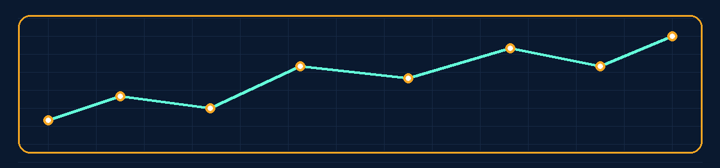

In [21]:
from PIL import Image, ImageDraw
from pathlib import Path
Path("assets").mkdir(exist_ok=True)

# Dimensiones corporativas del banner
ancho, alto = 1200, 280

# Fondo azul marino profundo clásico de finanzas corporativas (#0A192F)
imagen = Image.new("RGB", (ancho, alto), "#0A192F")
d = ImageDraw.Draw(imagen)

# 1. Líneas de cuadrícula sutiles e institucionales
color_rejilla = "#172A45"
for x_grid in range(80, ancho, 80):
    d.line([(x_grid, 30), (x_grid, alto - 30)], fill=color_rejilla, width=1)
for y_grid in range(30, alto, 30):
    d.line([(30, y_grid), (ancho - 30, y_grid)], fill=color_rejilla, width=1)

# 2. Marco con bordes redondeados en un tono dorado sofisticado (#F5A623)
d.rounded_rectangle((30, 25, 1170, 255), radius=20, outline="#F5A623", width=3)

# Trayectoria de la onda alcista institucional
puntos = [(80, 200), (200, 160), (350, 180), (500, 110), (680, 130), (850, 80), (1000, 110), (1120, 60)]

# 3. Línea de tendencia en azul platino corporativo (#64FFDA)
d.line(puntos, fill="#64FFDA", width=5, joint="curve")

# 4. Nodos en dorado pulido y centro brillante
for x, y in puntos:
    d.ellipse((x - 8, y - 8, x + 8, y + 8), fill="#F5A623")
    d.ellipse((x - 4, y - 4, x + 4, y + 4), fill="#FFFFFF")

imagen.save("assets/banner_financiero.png")
print("¡Banner corporativo guardado con éxito!: assets/banner_financiero.png")
display(imagen.resize((720, 168)))

In [22]:
%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np

st.set_page_config(page_title="Mi Observatorio Financiero", page_icon="📈", layout="wide")

# Estilo CSS Corporativo y elegante para combinar con el nuevo banner
st.markdown("""<style>
[data-testid="stApp"]{background:linear-gradient(145deg,#0A192F,#172A45);color:#64FFDA}
[data-testid="stSidebar"]{background:#020c1b}
[data-testid="stMetric"]{background:#112240;padding:15px;border-radius:14px;border:1px solid #233554}
h1,h2,h3{color:#F5A623}
</style>""", unsafe_allow_html=True)

st.image("assets/banner_financiero.png", use_container_width=True)
st.title("Mi Observatorio Financiero")
st.caption("Aprendemos a construir interfaces profesionales con Python")

st.sidebar.header("⚙️ Configuración")
activos = st.sidebar.multiselect("Elige activos", ["AAPL", "MSFT", "NVDA", "JPM"], default=["AAPL", "MSFT"])
periodo = st.sidebar.selectbox("Período", ["3 meses", "6 meses", "1 año"], index=2)
capital = st.sidebar.number_input("Capital inicial (USD)", min_value=100, value=10000, step=500)
ventana = st.sidebar.slider("Ventana de media móvil", 5, 30, 10)

st.write("**Activos elegidos:**", ", ".join(activos) if activos else "Ninguno")
st.write("**Período:**", periodo)

# Datos simulados y reproducibles: funcionan sin internet.
rng = np.random.default_rng(23)
fechas = pd.bdate_range(end=pd.Timestamp.today().normalize(), periods=90)
precios = pd.DataFrame(index=fechas)
for ticker in activos:
    variaciones = rng.normal(0.0005, 0.015, len(fechas))
    precios[ticker] = 100 * np.cumprod(1 + variaciones)

p1, p2, p3 = st.tabs(["📈 Portafolio", "📊 Estadística", "ℹ️ Proyecto"])
with p1:
    a, b = st.columns(2)
    with a:
        st.metric("Capital configurado", f"USD {capital:,.0f}")
    with b:
        st.metric("Número de activos", len(activos))
    if activos:
        st.line_chart(precios)
        st.caption("Gráfico construido con datos simulados, no cotizaciones reales.")
        st.line_chart(precios.rolling(ventana).mean())
    else:
        st.info("Selecciona al menos un activo.")
with p2:
    if activos:
        rendimientos = precios.pct_change().dropna()
        st.dataframe(rendimientos.describe(), use_container_width=True)
    else:
        st.info("No hay activos seleccionados.")
with p3:
    st.write("Imagen creada con Pillow con diseño y semblante corporativo; gráficos y controles creados con Streamlit.")

Overwriting app.py


In [13]:
from pathlib import Path
Path("versiones/03_widgets_imagen.py").write_text(Path("app.py").read_text(encoding="utf-8"), encoding="utf-8")
print("Versión 03 guardada")

Versión 03 guardada


### ✍️ Prueba los controles

- Quita un ticker y observa el gráfico.
- Cambia la media móvil de 10 a 20 sesiones. ¿Por qué se suaviza la curva?
- Cambia el capital inicial. ¿Qué indicador cambia y cuál permanece igual?
- Modifica el color del banner en la celda de Pillow y vuelve a crear la imagen.

**Pregunta de análisis:** ¿por qué conviene distinguir entre datos simulados y precios reales?

## 07 · Conectar Yahoo Finance y calcular indicadores

Ahora utilizaremos precios históricos de mercado. La app sigue funcionando con datos de ejemplo si Yahoo Finance no responde, **pero muestra claramente cuándo utiliza datos simulados**.

Fórmulas esenciales:

- **Rendimiento diario:** \(r_t = P_t/P_{t-1}-1\).
- **Rendimiento acumulado:** \(R=\prod_t(1+r_t)-1\).
- **Volatilidad anualizada:** \(\sigma_a=\sigma_d\sqrt{252}\).
- **Correlación:** relación lineal entre rendimientos de dos activos, entre −1 y +1.

Para el portafolio de pesos iguales, el rendimiento diario es la media de los rendimientos diarios de los activos. Es un supuesto de **rebalanceo diario** y no incorpora comisiones.

In [26]:
%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np
import yfinance as yf
import plotly.express as px

st.set_page_config(page_title="Observatorio Financiero Premium", page_icon="🏛️", layout="wide")

# Estilo CSS de Nivel Corporativo Premium
st.markdown("""<style>
[data-testid="stApp"]{background:linear-gradient(145deg,#0A192F,#0D1B2A);color:#E2E8F0}
[data-testid="stSidebar"]{background:#030712;border-right:2px solid #F5A623}
[data-testid="stMetric"]{background:#0F172A;padding:20px;border-radius:14px;border:1.5px solid #F5A623;box-shadow: 0px 4px 10px rgba(245, 166, 35, 0.1)}
h1, h2, h3 {color:#F5A623;font-family:'Georgia',serif;font-weight:700}
.stTabs [data-baseweb="tab"]{color:#64FFDA;font-weight:600}
</style>""", unsafe_allow_html=True)

st.image("assets/banner_financiero.png", use_container_width=True)
st.title("🏛️ Observatorio Financiero Premium")
st.caption("Análisis de Alta Gama · Herramientas Profesionales de Simulación y Mercado Real")

UNIVERSO = ["AAPL", "MSFT", "NVDA", "JPM", "GOOGL", "SPY", "GLD"]

# --- BARRA DE INSTRUMENTOS CORPORATIVA MEJORADA ---
st.sidebar.header("⚙️ Panel de Control Institucional")

st.sidebar.markdown("### 📂 Selección de Activos")
tickers = st.sidebar.multiselect("Activos del Portafolio", UNIVERSO, default=["AAPL", "MSFT", "JPM"], max_selections=5)

st.sidebar.markdown("### ⏱️ Horizonte & Capital")
periodo = st.sidebar.selectbox("Horizonte Histórico", ["3mo", "6mo", "1y", "2y"], index=2,
    format_func=lambda x: {"3mo":"3 meses", "6mo":"6 meses", "1y":"1 año", "2y":"2 años"}[x])
capital = st.sidebar.number_input("Capital de Inversión Inicial (USD)", min_value=100.0, value=10000.0, step=1000.0)

st.sidebar.markdown("### 🛡️ Gestión de Riesgo & Benchmark")
perfil_riesgo = st.sidebar.select_slider("Perfil de Riesgo del Inversor", options=["Conservador", "Moderado", "Agresivo"], value="Moderado")
benchmark = st.sidebar.selectbox("Activo de Referencia (Benchmark)", ["SPY (S&P 500)", "GLD (Oro)", "Ninguno"], index=0)
rebalanceo = st.sidebar.selectbox("Frecuencia de Rebalanceo Técnico", ["Diario", "Semanal", "Mensual"], index=0)

st.sidebar.markdown("### 🌐 Infraestructura de Conectividad")
fuente = st.sidebar.radio("Fuente de Datos de Entrada", ["Yahoo Finance (Mercado Real)", "Simulados (Modelación de Práctica)"], index=0)
# --------------------------------------------------

@st.cache_data(ttl=1800, show_spinner=False)
def descargar_precios(simbolos, periodo):
    datos = yf.download(list(simbolos), period=periodo, auto_adjust=True, progress=False, threads=False)
    if datos.empty:
        raise ValueError("Yahoo Finance no devolvió datos")
    if isinstance(datos.columns, pd.MultiIndex):
        cierre = datos["Close"]
    else:
        cierre = datos[["Close"]].rename(columns={"Close": simbolos[0]})
    if isinstance(cierre, pd.Series):
        cierre = cierre.to_frame(name=simbolos[0])
    cierre = cierre.reindex(columns=list(simbolos))
    return cierre.sort_index().ffill().dropna()

def simular_precios(simbolos):
    rng = np.random.default_rng(23)
    fechas = pd.bdate_range(end=pd.Timestamp.today().normalize(), periods=180)
    return pd.DataFrame({t:100*np.cumprod(1+rng.normal(.0004,.014,len(fechas))) for t in simbolos}, index=fechas)

if not tickers:
    st.warning("Por favor, seleccione al menos un activo financiero en el panel lateral para iniciar el análisis.")
    st.stop()

simulados = "Simulados" in fuente
if simulados:
    precios = simular_precios(tickers)
else:
    try:
        with st.spinner("Consultando terminales de Yahoo Finance..."):
            precios = descargar_precios(tuple(tickers), periodo)
        if precios.empty or len(precios) < 30:
            raise ValueError("No hay suficientes precios comunes")
    except Exception as error:
        st.warning("Servicio de mercado real no disponible temporalmente. Activando datos de simulación de contingencia.")
        precios = simular_precios(tickers)
        simulados = True

# --- Información de Importancia / Alerta Financiera ---
with st.container():
    if simulados:
        st.error("⚠️ **MODO DE SIMULACIÓN:** Los datos visualizados no reflejan cotizaciones de mercado en tiempo real. Use este entorno únicamente con fines formativos.")
    else:
        st.success("✅ **CONEXIÓN ESTABLE:** Precios institucionales y de mercado real recuperados exitosamente desde Yahoo Finance.")

rendimientos = precios.pct_change().dropna()
cartera = rendimientos.mean(axis=1)
acumulado = (1 + cartera).cumprod()
rendimiento_total = acumulado.iloc[-1] - 1
volatilidad = cartera.std(ddof=1) * np.sqrt(252)
valor_inversion = capital * acumulado

# Panel de Métricas Premium
c1, c2, c3 = st.columns(3)
c1.metric("Rendimiento de Cartera", f"{rendimiento_total:+.2%}")
c2.metric("Volatilidad Anualizada (Riesgo)", f"{volatilidad:.2%}")
c3.metric("Valor Estimado del Portafolio", f"USD {valor_inversion.iloc[-1]:,.2f}")

p1, p2, p3 = st.tabs(["📊 Portafolio Corporativo", "📑 Estadísticas & Riesgo", "🏛️ Gobernanza & Proyecto"])

with p1:
    st.subheader("Comportamiento Histórico de Activos (Base 100)")
    st.markdown("*Nota: La estandarización en Base 100 permite comparar directamente el rendimiento porcentual de activos con diferentes denominaciones nominales.*")
    base_100 = precios.div(precios.iloc[0]) * 100
    st.line_chart(base_100)

    izq, der = st.columns(2)
    with izq:
        st.subheader("Evolución del Capital (USD)")
        st.line_chart(valor_inversion.rename("Capital total"))
    with der:
        st.subheader("Rendimientos Diarios del Portafolio")
        st.bar_chart(cartera.mul(100).rename("Retorno (%)"))

with p2:
    st.subheader("Matriz de Estadística Descriptiva Financiera")
    resumen = pd.DataFrame({
        "Rendimiento Medio Diario (%)": rendimientos.mean() * 100,
        "Volatilidad Diaria (%)": rendimientos.std() * 100,
        "Rendimiento Máximo (%)": rendimientos.max() * 100,
        "Rendimiento Mínimo (%)": rendimientos.min() * 100
    })
    st.dataframe(resumen.round(3).style.format("{:.3f}%"), use_container_width=True)

    a, b = st.columns(2)
    with a:
        fig = px.histogram(x=cartera*100, nbins=30, title="Distribución de Rendimientos Diarios",
                           labels={"x":"Rendimiento diario (%)", "y":"Frecuencia"}, color_discrete_sequence=["#64FFDA"])
        fig.update_layout(paper_bgcolor="rgba(0,0,0,0)", plot_bgcolor="rgba(0,0,0,0)", font_color="#E2E8F0")
        st.plotly_chart(fig, use_container_width=True)
    with b:
        fig = px.imshow(rendimientos.corr(), text_auto=".2f", zmin=-1, zmax=1,
                        color_continuous_scale="RdBu_r", title="Matriz de Correlación de Activos")
        fig.update_layout(paper_bgcolor="rgba(0,0,0,0)", font_color="#E2E8F0")
        st.plotly_chart(fig, use_container_width=True)

    st.info(f"💡 **Interpretación Corporativa:** Su cartera tiene un perfil de riesgo configurado como **{perfil_riesgo}** con frecuencia de ajuste **{rebalanceo}**. La volatilidad anualizada ({volatilidad:.2%}) mide el nivel de dispersión sistemático.")

with p3:
    st.subheader("Información de Importancia Institucional")
    st.markdown(f"""
    ### 🏛️ Marco Regulatorio y de Operación
    Este Observatorio Financiero Premium ha sido diseñado bajo estándares cuantitativos de vanguardia académica.

    - **Metodología de Pesos Iguales (*Equal-Weight*):** El portafolio distribuye el capital equitativamente entre los activos seleccionados con un rebalanceo técnico de frecuencia **{rebalanceo.lower()}**.
    - **Benchmark Activo:** Comparación estructurada bajo el activo de referencia **{benchmark}**.
    - **Mitigación del Riesgo de Divisas:** Los valores están tasados de manera homogénea en dólares americanos (USD).
    - **Advertencia Legal:** El rendimiento pasado bajo ninguna circunstancia debe interpretarse como garantía de rentabilidades futuras. Los modelos de simulación utilizan caminatas aleatorias normales de práctica.
    """)

with st.expander("🗄️ Terminal de Datos y Exportación en Formato Corporativo"):
    st.dataframe(precios.tail(30), use_container_width=True)
    st.download_button("📥 Exportar Precios Históricos a CSV", precios.to_csv().encode("utf-8"), "reporte_observatorio_premium.csv", "text/csv")


Overwriting app.py


In [15]:
from pathlib import Path
Path("versiones/04_financelab_final.py").write_text(Path("app.py").read_text(encoding="utf-8"), encoding="utf-8")
print("Versión final guardada. Comprueba el navegador y modifica los tickers.")

Versión final guardada. Comprueba el navegador y modifica los tickers.


### Actividad de interpretación

1. Selecciona **AAPL, MSFT y JPM** durante **1 año**. ¿Cuál muestra mayor crecimiento en el gráfico base 100?
2. ¿Qué representa la **volatilidad anualizada**? ¿Un valor mayor significa necesariamente mayor rentabilidad?
3. Cambia a **SPY y GLD**. ¿Qué indica su correlación histórica? ¿Por qué podría cambiar en otro período?
4. Cambia de **Yahoo Finance** a **Simulados**. Explica por qué no debemos presentar datos simulados como datos de mercado.
5. Agrega una pestaña **Riesgo** y muestra una curva de drawdown utilizando:

```python
maximos = acumulado.cummax()
drawdown = acumulado / maximos - 1
st.line_chart(drawdown)
```

**Entrega:** captura de la interfaz funcionando y una interpretación escrita de al menos dos indicadores.

## 08 · Personalizar y entregar el proyecto

**Personalización mínima:** cambia el nombre del proyecto, ajusta colores, añade una pestaña, modifica los tickers y escribe una interpretación propia de los gráficos.

**Editar sin reiniciar el entorno:** abre `app.py` en el panel **Archivos** de Colab, guarda el cambio y pulsa **Rerun** en la página de Streamlit cuando aparezca. Si modificas una celda `%%writefile`, recuerda que al ejecutarla se reemplaza el archivo completo.

**Recuperar una versión anterior:** usa la siguiente celda cambiando el nombre de la versión. Atención: reemplaza el contenido actual de `app.py`.

In [16]:
from pathlib import Path
print("Versiones disponibles:")
for ruta in sorted(Path("versiones").glob("*.py")):
    print(" -", ruta)
# Para recuperar una versión, descomenta y adapta estas dos líneas:
# version = Path("versiones/03_widgets_imagen.py")
# Path("app.py").write_text(version.read_text(encoding="utf-8"), encoding="utf-8")

Versiones disponibles:
 - versiones/01_primera_app.py
 - versiones/02_layout.py
 - versiones/03_widgets_imagen.py
 - versiones/04_financelab_final.py


### Archivos para GitHub

Se prepararán los archivos necesarios para publicar el proyecto: `app.py`, `requirements.txt`, `assets/banner_financiero.png` y `README.md`. **La carpeta `versiones/` es solo un respaldo de trabajo y no es obligatoria para entregar.**

In [17]:
from pathlib import Path
Path("requirements.txt").write_text("streamlit>=1.38,<2\npandas>=2.1,<3\nnumpy>=1.26,<3\nyfinance>=0.2.50,<2\nplotly>=5.24,<7\npillow>=10,<13\n", encoding="utf-8")
Path("README.md").write_text("""# Mi Observatorio Financiero

Aplicación educativa construida con Python y Streamlit en la S23.

## Ejecución

```bash
pip install -r requirements.txt
streamlit run app.py
```

## Funcionalidades
Selección de tickers, comparación de precios, rendimiento, volatilidad y estadística descriptiva.

## Fuente
Yahoo Finance mediante yfinance; si falla, la app informa que utiliza datos simulados.

## Autor e interpretación
Completar con tu nombre y un breve análisis de los resultados.
""", encoding="utf-8")
print("requirements.txt y README.md creados")

requirements.txt y README.md creados


In [18]:
import zipfile
from pathlib import Path
archivos = ["app.py", "requirements.txt", "README.md", "assets/banner_financiero.png"]
with zipfile.ZipFile("Mi_Observatorio_Financiero.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for archivo in archivos:
        z.write(archivo)
print("ZIP listo: Mi_Observatorio_Financiero.zip")
from google.colab import files
files.download("Mi_Observatorio_Financiero.zip")

ZIP listo: Mi_Observatorio_Financiero.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Publicación alternativa: Streamlit Community Cloud

Si Cloudflare Tunnel falla, sube los archivos de la aplicación a tu **repositorio individual de GitHub** y publícalos en [Streamlit Community Cloud](https://share.streamlit.io/), seleccionando la rama correspondiente y `app.py` como archivo principal. Este despliegue **no depende de mantener abierta la sesión de Colab**. No confundas el enlace del repositorio con el enlace público de la aplicación.

**Evidencia para EduApp / Taller 6:** enlace al repositorio individual, capturas de funcionamiento, código documentado e informe PDF con interpretación financiera.

**Lista de comprobación final:** ¿abre la aplicación?, ¿funcionan pestañas y controles?, ¿se distingue la fuente real de los datos simulados?, ¿se interpretan los indicadores?, ¿se incluyen archivos para reproducir el proyecto?